# **Qual é o problema?**

Hoje nós vamos discutir sobre streaming de dados estruturados no contexto de aplicações que utilizam inteligência artificial generativa.
O problema em si é datado, mas passou a ser mais aparente com a expansão de sistemas dependentes das respostas de Large Language Models, esses que geram pedaços de texto de forma gradual até sua completude. Portanto, o nosso objetivo aqui é explorar uma estratégia de streaming estruturado baseada no padrão JSON Schema.

Esse padrão segue alguns princípios:
1. **Aspas Duplas:** cada chave sempre estará envolta de aspas
2. **Tipos**: o valor pode ser string, number, boolean, object (representado por chaves "{}", array (representado por colchetes "[]") ou null.
3. **Aninhamento**: os valores podem gerar aninhamento, como por exemplo uma array contendo objetos ou objetos contendo outros objetos/array internamente.
4. **Vírgula**: a separação de cada par chave - valor ocorre por meio da vírgula.
5. **Dois pontos (:)**: a chave é separada do valor pelo uso de dois pontos. Ex: `{"chave":"valor"}`

Todas essas regras são essenciais para desmembrar os tratamentos necessários para criação de um algoritmo que consiga lidar com essa estrutura.

A ponto 3 é super importante, pois quando falamos de dados aninhados e combinados podemos nos deparar com inúmeras possibilidades que permitem a representação de estruturas mais complexas.


# **Proposta**

Nas seções adiantes serão apresentados os módulos que compõem um algoritmo capaz de receber um esquema JSON incompleto e retornar um formato parcialmente correto.

Atualmente, os modelos geram output estruturado com base nas instruções passadas como input; ou seja, ao solicitar *"responda substituindo os espaços por _"* o modelo provavelmente acertará sua requisição e devolverá uma resposta com sublinhas onde deveriam estar espaços. É esse mesmo mecanismo que é aplicado quando passamos um formato de resposta em bibliotecas como Langchain ou em chamadas diretas as APIs dos provedores.

Com base na confiança de que a resposta gerada estará dentro dos parâmetros requeridos no output, podemos implementar uma estratégia de recebimento desses dados.

De modo geral, o algoritmo faz uso dos seguintes itens:
- Um buffer de memória para persistir o estado (tokens recebidos)
- Um fluxo de iteração sobre uma lista de caracteres (todo texto pode ser representado por uma lista de caracteres)
- A detecção de início e fim das chaves e valores com base nos princípios básicos do JSON.
- Recursividade para conseguir tratar dados aninhados e/ou incompletos

# **Utilidade**

A economia de recursos (memória e processamento), a rapidez de acesso e a entrega incremental são todos benefícios do envio separado dos pedaços pertencentes a um todo.

Novamente, os modelos de inteligência artificial podem (ou não) gerar dados estruturados. No caso negativo, é possível utilizar os pedaços da própria resposta sem tratamento algum; o problema que queremos tratar aqui é o oposto.

Para esse caso é possível citar dois exemplos comuns:
- módulos conversacionais com menor tempo de latência entre a apresentação da resposta dos agentes para o usuário e o TTFT(time-to-first-token).
- gráficos com efeito de carregamento contínuo (enquanto o modelo gera a *series* de dados, você alimenta a interface.)

In [ ]:
from IPython.display import Image

# Exemplo de streaming, copiado de https://medium.com/@ansilproabl/streaming-llm-responses-in-real-time-705b8784fae5.
Image(url='https://miro.medium.com/v2/resize:fit:1100/format:webp/1*qh8Hcv8NIEUodZ5BpUgOIQ.gif')

# **Implementação**
Nos próximos passos nós iremos demonstrar uma alternativa para o tratamento de streaming estruturado utilizando uma técnica incremental e recursiva.

A implementação é incremental, pois acumula e trata uma memória a partir do recebimento de pequenas partes em sequência, e também é recursiva pelo tratamento aninhado de cada um dos tipos de dados possíveis em JSON.

Para facilitar o entendimento, vamos utilizar como exemplo dois personagens clássicos da DC Comics.

***Atenção: para as próximas etapas é necessário entender o básico de:***

-[ Python / Dataclass / Pydantic](https://pydantic.dev/docs/validation/dev/get-started/)
-[ Completions API](https://developers.openai.com/api/docs/guides/completions)
-[JSON Schema Standard](https://json-schema.org/specification)


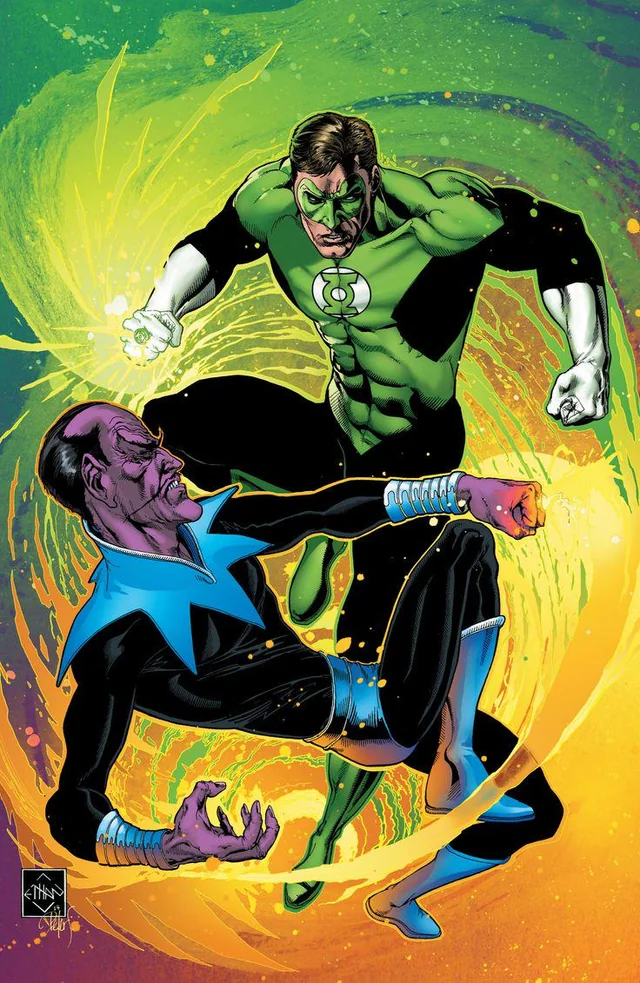

In [ ]:
# Altere os valores abaixo para adaptar as tratativas
sinestro = {"name": "Sinestro", "age": 42, "hero": False, "likes": ["confusion", "war", "beer"]}
green_lantern = {"name": "Hal Jordan", "age": 55, "hero": True, "likes": ["to help people", "fly", "beer"], "archenemy": sinestro}

Pensando nos tipos primários de dados nós começaremos definindo funções para o tratamento e identificação de cada um desses tipos.

Aqui, o notebook em si funciona como o estado do *parser*: variáveis globais representam o *buffer* de texto (`src`) e a posição atual do cursor (`i`). Funções auxiliares como `skip_ws` e `peek` operam sobre esse estado compartilhado.

In [ ]:
src = ""
i = 0
n = 0
TRACE = False
_log_depth = 0

# Pula caracteres em branco ou espaços entre pedaços do JSON como um \n,
# por exemplo
def skip_ws():
    global i
    while i < n and src[i].isspace():
        i += 1

# Verifica o caractere atual do index
def peek():
    return src[i] if i < n else ""


# Auxiliar para pretty print
def _preview(value, limit=55):
    text = repr(value)
    return text if len(text) <= limit else text[: limit - 3] + "..."

# Auxiliar para pretty print
def log_enter(name):
    global _log_depth
    if not TRACE:
        return
    print(f"{'  ' * _log_depth}▸ {name}")
    _log_depth += 1


# Auxiliar para pretty print
def log_exit(name, value, ready):
    global _log_depth
    if not TRACE:
        return
    _log_depth -= 1
    badge = "✓ pronto" if ready else "… parcial"
    print(f"{'  ' * _log_depth}└─ {name} [{badge}] {_preview(value)}")


def reset_trace():
    global _log_depth
    _log_depth = 0

### `parse_number`

Números JSON podem ser inteiros (`42`), decimais (`3.14`) ou notação científica (`1e-2`). Com a regra  definida na função de distribuição, ao chegar nessa função temos certeza de que o caractere atual (i) esta em '-0123456789', portanto precisamos verificar os próximos valores para confirmar se a sequência é um número válido ou não. A função consome o token caractere a caractere e só considera o valor **pronto** quando forma um número válido.

Após a tentativa de montar o token numérico, verificamos no final

    `if not token or token in "-." or token[-1] in ".eE+-"`
Pois se o token gerado for pedaços como `-`, `.`, `-.`, ou ter qualquer um dos ".eE+-" no final, como `1.` ou `1e` então eles ainda estão incompletos — retornamos `(None, False)` para que o próximo chunk possa continuar a leitura.

In [ ]:
def parse_number():
    log_enter("parse_number")
    global i
    start = i
    if peek() == "-":
        i += 1
    while i < n and src[i].isdigit():
        i += 1
    if peek() == ".":
        i += 1
        while i < n and src[i].isdigit():
            i += 1
    if peek() in "eE":
        i += 1
        if peek() in "+-":
            i += 1
        while i < n and src[i].isdigit():
            i += 1

    token = src[start:i]
    if not token or token in "-." or token[-1] in ".eE+-":
        log_exit("parse_number", None, False)
        return None, False
    try:
        if "." in token or "e" in token or "E" in token:
            value = float(token)
        else:
            value = int(token)
        log_exit("parse_number", value, True)
        return value, True
    except ValueError:
        log_exit("parse_number", None, False)
        return None, False

### `parse_string`

Strings JSON começam e terminam com aspas duplas. A função trata escapes comuns (`\n`, `\t`, `\"`, etc.) e suporta unicode (`\u0041`) para permitir conversão ASCII sem erros.

Relembrando das regras do padrão JSON sabemos que não somente valores textuais, mas também as chaves são definidas envoltas de aspas, dessa forma, o parse_string é usado toda vez que o início de uma nova chave é detectada!

Se a aspa de fechamento ainda não chegou, devolvemos o texto parcial com `ready=False` — isso permite exibir o conteúdo incrementalmente na interface enquanto o modelo ainda está gerando.

In [ ]:
def parse_string():
    log_enter("parse_string")
    global i
    if peek() != '"':
        log_exit("parse_string", None, False)
        return None, False
    i += 1
    chars = []
    while i < n:
        char = src[i]
        if char == '"':
            i += 1
            value = "".join(chars)
            log_exit("parse_string", value, True)
            return value, True
        if char == "\\":
            if i + 1 >= n:
                value = "".join(chars)
                log_exit("parse_string", value, False)
                return value, False
            esc = src[i + 1]
            mapping = {
                "n": "\n",
                "t": "\t",
                "r": "\r",
                '"': '"',
                "\\": "\\",
                "/": "/",
            }
            if esc in mapping:
                chars.append(mapping[esc])
                i += 2
                continue
            if esc == "u" and i + 5 < n:
                hex_code = src[i + 2 : i + 6]
                try:
                    chars.append(chr(int(hex_code, 16)))
                    i += 6
                    continue
                except ValueError:
                    pass
            chars.append(esc)
            i += 2
            continue
        chars.append(char)
        i += 1
    value = "".join(chars)
    log_exit("parse_string", value, False)
    return value, False

### `parse_object`

Objetos JSON são delimitados por `{` e `}`. Para cada par chave-valor, lemos a chave (sempre string), consumimos `:`, e então chamamos `parse_value` para o valor.

Em streaming, mantemos chaves cujo nome já fechou e incluímos valores parciais de tipos compostos (string, object, array) enquanto ainda crescem. Escalares só entram quando estão completos. `ready=True` somente após o `}` de fechamento.

In [ ]:
def parse_object():
    log_enter("parse_object")
    global i
    if peek() != "{":
        log_exit("parse_object", {}, False)
        return {}, False
    i += 1
    result = {}

    while True:
        skip_ws()
        if i >= n:
            log_exit("parse_object", result, False)
            return result, False
        if peek() == "}":
            i += 1
            log_exit("parse_object", result, True)
            return result, True
        if peek() != '"':
            log_exit("parse_object", result, False)
            return result, False

        key, key_done = parse_string()
        if not key_done or key is None:
            log_exit("parse_object", result, False)
            return result, False

        skip_ws()
        if peek() != ":":
            log_exit("parse_object", result, False)
            return result, False
        i += 1

        value, value_ready = parse_value()
        if value_ready or (
            isinstance(value, (str, dict, list)) and value is not None
        ):
            if value is not None:
                result[key] = value

        skip_ws()
        if peek() == ",":
            i += 1
            continue
        if peek() == "}":
            i += 1
            log_exit("parse_object", result, True)
            return result, True
        log_exit("parse_object", result, False)
        return result, False

### `parse_array`

Arrays JSON são delimitados por `[` e `]`. Cada item é parseado via `parse_value`. Itens finalizados permanecem na lista; o último item pode ainda estar parcial (string aberta, objeto aninhado incompleto).

`ready=True` somente após o `]` de fechamento.

In [ ]:
def parse_array():
    log_enter("parse_array")
    global i
    if peek() != "[":
        log_exit("parse_array", [], False)
        return [], False
    i += 1
    items = []

    while True:
        skip_ws()
        if i >= n:
            log_exit("parse_array", items, False)
            return items, False
        if peek() == "]":
            i += 1
            log_exit("parse_array", items, True)
            return items, True

        value, value_ready = parse_value()
        if value_ready or isinstance(value, (str, dict, list)):
            if value is not None:
                items.append(value)

        skip_ws()
        if peek() == ",":
            i += 1
            continue
        if peek() == "]":
            i += 1
            log_exit("parse_array", items, True)
            return items, True
        log_exit("parse_array", items, False)
        return items, False

### `parse_boolean`

Booleanos JSON são os literais `true` ou `false`, sem aspas. A função verifica se o texto restante começa com um desses tokens e se ele está **delimitado** — ou seja, seguido por espaço, vírgula, `}` ou `]`.

Um prefixo como `tru` (enquanto aguardamos `true`) é incompleto: o cursor não avança e retornamos `(None, False)`.

In [ ]:
def parse_boolean():
    log_enter("parse_boolean")
    global i
    remaining = src[i:]
    for token, value in [("true", True), ("false", False)]:
        if remaining.startswith(token):
            next_char = remaining[len(token) : len(token) + 1]
            if next_char and next_char not in ",]} \t\n\r":
                log_exit("parse_boolean", None, False)
                return None, False
            i += len(token)
            log_exit("parse_boolean", value, True)
            return value, True
        if token.startswith(remaining) and remaining:
            log_exit("parse_boolean", None, False)
            return None, False
    log_exit("parse_boolean", None, False)
    return None, False

### `parse_null`

O valor `null` segue a mesma lógica dos booleanos: é um literal fixo que precisa estar completo e delimitado. Um prefixo como `nu` indica que o stream ainda não terminou de enviar o token.

In [ ]:
def parse_null():
    log_enter("parse_null")
    global i
    remaining = src[i:]
    token = "null"
    value = None
    if remaining.startswith(token):
        next_char = remaining[len(token) : len(token) + 1]
        if next_char and next_char not in ",]} \t\n\r":
            log_exit("parse_null", None, False)
            return None, False
        i += len(token)
        log_exit("parse_null", value, True)
        return value, True
    if token.startswith(remaining) and remaining:
        log_exit("parse_null", None, False)
        return None, False
    log_exit("parse_null", None, False)
    return None, False

### Unificando literais: `match_literal`

`parse_boolean` e `parse_null` repetem a mesma estratégia: comparar o texto restante com um token fixo, checar delimitadores e lidar com prefixos incompletos. Por isso, na implementação final, eles são consolidados em uma única função `match_literal(token, value)` — chamada três vezes com `("true", True)`, `("false", False)` e `("null", None)`.

Essa abstração reduz duplicação sem alterar o comportamento em streaming.

In [ ]:
def match_literal(token, value):
    log_enter(f"match_literal({token!r})")
    global i
    remaining = src[i:]
    if remaining.startswith(token):
        next_char = remaining[len(token) : len(token) + 1]
        if next_char and next_char not in ",]} \t\n\r":
            log_exit(f"match_literal({token!r})", None, False)
            return None, False
        i += len(token)
        log_exit(f"match_literal({token!r})", value, True)
        return value, True
    if token.startswith(remaining) and remaining:
        log_exit(f"match_literal({token!r})", None, False)
        return None, False
    log_exit(f"match_literal({token!r})", None, False)
    return None, False

### `parse_value` — central de distribuição

Objetos e arrays dependem de um despachante que identifica o tipo do próximo valor pelo primeiro caractere (ou literal) e delega para a função correta. Execute esta célula após definir todas as funções acima para amarrar o fluxo recursivo.

In [ ]:
def parse_value():
    log_enter("parse_value")
    skip_ws()
    if i >= n:
        log_exit("parse_value", None, False)
        return None, False

    char = src[i]
    if char == "{":
        value, ready = parse_object()
        log_exit("parse_value", value, ready)
        return value, ready
    if char == "[":
        value, ready = parse_array()
        log_exit("parse_value", value, ready)
        return value, ready
    if char == '"':
        value, ready = parse_string()
        log_exit("parse_value", value, ready)
        return value, ready
    if char in "-0123456789":
        value, ready = parse_number()
        log_exit("parse_value", value, ready)
        return value, ready

    result, ready = match_literal("true", True)
    if ready:
        log_exit("parse_value", result, ready)
        return result, ready
    result, ready = match_literal("false", False)
    if ready:
        log_exit("parse_value", result, ready)
        return result, ready
    result, ready = match_literal("null", None)
    if ready:
        log_exit("parse_value", result, ready)
        return result, ready

    log_exit("parse_value", None, False)
    return None, False

## Etapa final — streaming de `green_lantern`

Como já discutimos na prática, o modelo não envia o JSON de uma vez: chegam **chunks** de texto que vão sendo acumulados em um buffer. A cada novo pedaço, reparseamos o buffer inteiro do zero e montamos o objeto parcialmente — exatamente como faríamos em uma aplicação real com LangGraph ou SSE.

Ajuste `CHUNK_SIZE` (quantos caracteres chegam por vez) e `CHUNK_DELAY` (pausa em segundos entre chunks) para controlar a velocidade da simulação. Com `TRACE = True`, cada função de parse imprime sua etapa em árvore.

In [ ]:
import json
import time

CHUNK_SIZE = 12
CHUNK_DELAY = 0.15


def _banner(title, width=62):
    line = "═" * width
    print(f"\n{line}\n  {title}\n{line}")


def _chunk_box(step, total, chunk, received, payload_len):
    bar_len = 30
    filled = int(bar_len * received / payload_len) if payload_len else 0
    bar = "█" * filled + "░" * (bar_len - filled)
    print(f"\n┌─ chunk {step:>2}/{total}  [{bar}]  {received}/{payload_len} chars")
    print(f"│  +{len(chunk)} chars → {chunk!r}")
    print(f"└{'─' * 60}")


def _pretty_json(data):
    body = json.dumps(data, indent=2, ensure_ascii=False)
    return "\n".join(f"    {line}" for line in body.splitlines())


def stream_green_lantern(obj=green_lantern):
    global src, i, n, TRACE

    payload = json.dumps(obj, ensure_ascii=False)
    buffer = ""
    total = (len(payload) + CHUNK_SIZE - 1) // CHUNK_SIZE

    _banner(
        f"DEMO · streaming incremental · chunk={CHUNK_SIZE} · delay={CHUNK_DELAY}s"
    )
    print(f"  payload ({len(payload)} chars):\n    {payload}")

    for step in range(1, total + 1):
        start = (step - 1) * CHUNK_SIZE
        chunk = payload[start : start + CHUNK_SIZE]
        buffer += chunk

        _chunk_box(step, total, chunk, len(buffer), len(payload))

        src = buffer
        n = len(src)
        i = 0
        reset_trace()
        TRACE = True

        print("\n  árvore de parse:")
        value, ready = parse_value()
        TRACE = False

        snapshot = value if isinstance(value, dict) else {}
        status = "fechado ✓" if ready else "ainda aberto …"

        print("\n  objeto montado:")
        print(_pretty_json(snapshot) if snapshot else "    {}")
        print(f"\n  status raiz: {status}")

        if step < total:
            time.sleep(CHUNK_DELAY)

    _banner("fim do stream")
    return snapshot


resultado = stream_green_lantern()


══════════════════════════════════════════════════════════════
  DEMO · streaming incremental · chunk=12 · delay=0.15s
══════════════════════════════════════════════════════════════
  payload (191 chars):
    {"name": "Hal Jordan", "age": 55, "hero": true, "likes": ["to help people", "fly", "beer"], "archenemy": {"name": "Sinestro", "age": 42, "hero": false, "likes": ["confusion", "war", "beer"]}}

┌─ chunk  1/16  [█░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]  12/191 chars
│  +12 chars → '{"name": "Ha'
└────────────────────────────────────────────────────────────

  árvore de parse:
▸ parse_value
  ▸ parse_object
    ▸ parse_string
    └─ parse_string [✓ pronto] 'name'
    ▸ parse_value
      ▸ parse_string
      └─ parse_string [… parcial] 'Ha'
    └─ parse_value [… parcial] 'Ha'
  └─ parse_object [… parcial] {'name': 'Ha'}
└─ parse_value [… parcial] {'name': 'Ha'}

  objeto montado:
    {
      "name": "Ha"
    }

  status raiz: ainda aberto …

┌─ chunk  2/16  [███░░░░░░░░░░░░░░░░░░░░░░░░░░░]  2

# Aprimoramentos

## Limpeza prévia

Assumir que o formato enviado pelo modelo será sempre a string JSON é arriscado, alguns modelos geram o resultado dentro de blocos de código como


```
'```json --> aqui é a identificação do bloco de código
{ --> aqui se inicia o JSON
  "name":"example"
}
'```
```

Tratar esses blocos previamente é uma etapa essencial antes do início do algoritmo principal, principalmente quando lidando com modelos menores.


## Mapeamento de campos

Nos sistemas atuais, esquemas JSON usualmente nascem a partir da conversão de modelos BaseModel (Pydantic) ou de dataclasses; ter essa estrutura definida em código permite modularizar a aplicação e fazer uso de diversas camadas de controle.

Uma possível etapa a ser implementada no algoritmo apresentado é a identificação dos campos para remover / anular qualquer geração extra (alucinação) que fuja do esquema definido e também para incluir identificação de tipos e aplicação de prévia e posterior inicialização de um objeto.

Hoje se o modelo gerar um campo extra ou um campo que fuja do seu tipo, não é possível identificar no momento de recebimento.

## Tratamento Intermediário

Aqui as possibilidades são tremendas, qualquer tipo de processamento pode ser feito em cima do valor parcial.

Um exemplo é disparar fluxos antes do recebimento completo da resposta. Se um campo é usado para afirmar que outro módulo paralelo deve ser executado, não é necessário esperar a completude; utilizando o resultado parcial há maior eficiência em alguns casos.

## Suporte a tipos diversos

Date, datetime, tuples, sets, são todos tipos de dados não suportados diretamente em JSON, e suportados em Python que precisam de uma maior atenção para correta conversão antes de posterior utilização ou envio a outro sistema.